Specify The case

In [1]:
param = 1

# Importing Libraries, defining variables, models etc

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import pandas as pd
import matplotlib.tri as mtri

Checking for GPU if available

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using device: cpu


Variables for model

In [4]:
# Step 1: Define problem

L = 1.0  # length of the domain
x_min, x_max = 0.0, L
y_min, y_max = 0.0, L
t_min, t_max = 0.0, 3000.0

# dimensionality
input_dim = 3   # (x, y, t)
output_dim = 1  # C only
F = 0.037
k = 0.06

Defining Models

In [32]:
n_fourier = 128                    # number of random frequencies (embedding dim = 2*n_fourier)
sigma_x, sigma_y, sigma_t = 5.0, 5.0, 2.0   # <-- tune these

In [33]:
class FourierFeatures(nn.Module):
    def __init__(self, in_dim=3, n_features=128, sigmas=(5.0, 5.0, 2.0), seed=0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        B = torch.randn(in_dim, n_features, generator=g)
        B = B * torch.tensor(sigmas, dtype=torch.float32).view(-1, 1)
        self.register_buffer("B", B)   # fixed, moves with .to(device), saved in state_dict

    def forward(self, X):
        proj = 2.0 * np.pi * X @ self.B
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)

In [34]:
class u_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = FourierFeatures(
            in_dim=3, n_features=n_fourier,
            sigmas=(sigma_x, sigma_y, sigma_t), seed=1
        )
        self.network = nn.Sequential(
            nn.Linear(2 * n_fourier, 64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # X: normalized (x, y, t) in [-1, 1]
        return self.network(self.embed(X))


In [20]:
class v_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = FourierFeatures(
            in_dim=3, n_features=n_fourier,
            sigmas=(sigma_x, sigma_y, sigma_t), seed=2
        )
        self.network = nn.Sequential(
            nn.Linear(2 * n_fourier, 64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # X: normalized (x, y, t) in [-1, 1]
        return self.network(self.embed(X))


Mounting Drive

In [7]:
# from google.colab import drive
# drive.mount('/content/drive',force_remount=True)

In [8]:
import pandas as pd

# Path to the file in Google Drive
file_path = fr"C:\Users\Karan\Desktop\PINNS_literature_review\gray_scott_model\data\data_{param}.txt"

# Generate column names
times = range(0, 3001, 10)

columns = ["x", "y"]

for t in times:
    columns += [f"u_{t}", f"v_{t}"]

# Read the data
df = pd.read_csv(
    file_path,
    sep=r"\s+",
    comment="%",
    header=None,
    names=columns
)

# Display the DataFrame
print(df)

              x         y  u_0           v_0  u_10          v_10  u_20  \
0      0.000000  0.000000  1.0  6.044687e-78   1.0  2.204048e-58   1.0   
1      0.001818  0.000000  1.0  1.862587e-77   1.0  2.288148e-58   1.0   
2      0.000000  0.001818  1.0  1.862587e-77   1.0  2.288148e-58   1.0   
3      0.001818  0.001818  1.0  6.161572e-77   1.0  2.375532e-58   1.0   
4      0.000000  0.003970  1.0  9.483544e-77   1.0  2.614471e-58   1.0   
...         ...       ...  ...           ...   ...           ...   ...   
10196  0.993544  0.993544  1.0  6.523927e-74   1.0  5.084951e-58   1.0   
10197  0.996030  0.990724  1.0  6.075878e-74   1.0  5.649834e-58   1.0   
10198  0.993544  0.996030  1.0  1.106928e-74   1.0  3.970411e-58   1.0   
10199  0.996030  0.993544  1.0  1.106928e-74   1.0  3.970411e-58   1.0   
10200  0.996030  0.996030  1.0  1.961715e-75   1.0  3.103192e-58   1.0   

               v_20  u_30          v_30  ...    u_2960    v_2960    u_2970  \
0      3.249821e-46   1.0  2.4514

In [9]:
def normalize(x, xmin, xmax):
    return 2.0 * (x - xmin) / (xmax - xmin) - 1.0

In [10]:
D_SCALE = 1e-5   # characteristic magnitude of the diffusion coefficients

class Du_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )

    def forward(self, X):
        # network output is O(1); scale it and keep it positive
        return D_SCALE * torch.nn.functional.softplus(self.network(X))


class Dv_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.Dv_raw = nn.Parameter(torch.tensor(1.0))   # O(1) parameter -> Dv about 1.3e-5 at init

    def value(self):
        return D_SCALE * torch.nn.functional.softplus(self.Dv_raw)

    def forward(self, X):
        return self.value() * torch.ones_like(X[:, 0:1])   # shape (N,1)

In [11]:
def make_D_fns(Du_nn, Dv_nn):
    def Du_fn(x, y):
        return Du_nn(torch.cat([normalize(x, x_min, x_max), normalize(y, y_min, y_max)], dim=1))
    def Dv_fn(x, y):
        return Dv_nn(torch.cat([normalize(x, x_min, x_max), normalize(y, y_min, y_max)], dim=1))
    return Du_fn, Dv_fn

# Running only pretrained models

In [25]:
def load_model_pretrained(model_name):

    pretrain_path = f"C:\\Users\\Karan\\Desktop\\PINNS_literature_review\\gray_scott_model\\models\\pretrained\\checkpoints_{param}\\{model_name}"

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    ckpt = torch.load(pretrain_path, map_location=device)

    u_nn = u_net().to(device)
    v_nn = v_net().to(device)
    u_nn.load_state_dict(ckpt["u_state_dict"])
    v_nn.load_state_dict(ckpt["v_state_dict"])

    # Sanity check: the normalization bounds must match the ones used in pre-training
    # current = dict(x_min=float(x_min), x_max=float(x_max),
    #             y_min=float(y_min), y_max=float(y_max),
    #             t_min=float(t_min), t_max=float(t_max))
    # assert all(abs(ckpt["bounds"][k] - current[k]) < 1e-9 for k in current), \
    #     f"Bounds mismatch! saved={ckpt['bounds']} current={current}"

    print("Loaded pre-trained u_nn and v_nn.")

    return u_nn,v_nn

## Specify Name of the model below

In [35]:
model_name = "uv_1000_pts_pretrained_nov.pt"

u_nn,v_nn = load_model_pretrained(model_name)

Loaded pre-trained u_nn and v_nn.


# Evaluating pre trained models

In [27]:
def evaluate_pretrained(plot_times,u_nn,v_nn):
    # ---------------------------------------------------------
    # Settings
    # ---------------------------------------------------------
    # plot_times = [0, 500, 1500, 3000]   # multiples of 10 in [0, 3000]

    # True diffusion coefficients
    D_true_fn = lambda x, y: 2e-5 * (1 + np.sin(np.pi * x) * np.sin(np.pi * y))
    Dv_true = 1e-5

    # ---------------------------------------------------------
    # Mesh from the data
    # ---------------------------------------------------------
    x_all = df["x"].values
    y_all = df["y"].values
    triang = mtri.Triangulation(x_all, y_all)

    x_t = torch.tensor(x_all, dtype=torch.float32, device=device).reshape(-1, 1)
    y_t = torch.tensor(y_all, dtype=torch.float32, device=device).reshape(-1, 1)

    # ---------------------------------------------------------
    # Predictions
    # ---------------------------------------------------------
    @torch.no_grad()
    def predict_uv(t_val):
        t_t = torch.full_like(x_t, float(t_val))
        X = torch.cat([
            normalize(x_t, x_min, x_max),
            normalize(y_t, y_min, y_max),
            normalize(t_t, t_min, t_max)
        ], dim=1)
        return u_nn(X).cpu().numpy().ravel(), v_nn(X).cpu().numpy().ravel()

    @torch.no_grad()
    def predict_D():
        X = torch.cat([
            normalize(x_t, x_min, x_max),
            normalize(y_t, y_min, y_max)
        ], dim=1)
        return Du_nn(X).cpu().numpy().ravel()

    # ---------------------------------------------------------
    # Heatmap helper
    # ---------------------------------------------------------
    def heat(ax, values, title, vmin=None, vmax=None, cmap="viridis"):
        cf = ax.tripcolor(triang, values, shading="gouraud", cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")
        plt.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)

    # ---------------------------------------------------------
    # u and v: true | estimated | |error|, one row per time
    # ---------------------------------------------------------
    preds = {t: predict_uv(t) for t in plot_times}

    for field, idx in [("u", 0), ("v", 1)]:
        n = len(plot_times)
        fig, axes = plt.subplots(n, 3, figsize=(15, 4.3 * n), squeeze=False)

        for i, t in enumerate(plot_times):
            true = df[f"{field}_{t}"].values
            pred = preds[t][idx]
            err = np.abs(pred - true)

            vmin = min(true.min(), pred.min())
            vmax = max(true.max(), pred.max())

            heat(axes[i, 0], true, f"True {field}(x,y), t={t}", vmin, vmax)
            heat(axes[i, 1], pred, f"Estimated {field}(x,y), t={t}", vmin, vmax)
            heat(axes[i, 2], err,  f"|Error|, t={t}", cmap="magma")

        plt.tight_layout()
        plt.show()

In [28]:
def metrics(u_nn, v_nn, chunk_size=500_000, held_out_only=False):
    times = np.arange(0, 3001, 10)
    n_t = len(times)
    n_pts = len(df)

    # --- Inputs: point-major ordering (all times for point 0, then point 1, ...) ---
    x_all = np.repeat(df["x"].values, n_t)
    y_all = np.repeat(df["y"].values, n_t)
    t_all = np.tile(times, n_pts)
    X = np.column_stack([x_all, y_all, t_all]).astype(np.float32)

    # --- Ground truth, shape (n_pts, n_t) ---
    u_true = df[[f"u_{t}" for t in times]].values.astype(np.float64)
    v_true = df[[f"v_{t}" for t in times]].values.astype(np.float64)

    # --- Predictions (in chunks, on the GPU) ---
    u_nn.eval(); v_nn.eval()
    u_pred, v_pred = [], []
    with torch.no_grad():
        for i in range(0, len(X), chunk_size):
            Xc = torch.from_numpy(X[i:i + chunk_size]).to(device)
            Xn = torch.cat([normalize(Xc[:, 0:1], x_min, x_max),
                            normalize(Xc[:, 1:2], y_min, y_max),
                            normalize(Xc[:, 2:3], t_min, t_max)], dim=1)
            u_pred.append(u_nn(Xn).cpu().numpy().ravel())
            v_pred.append(v_nn(Xn).cpu().numpy().ravel())

    u_pred = np.concatenate(u_pred).reshape(n_pts, n_t).astype(np.float64)
    v_pred = np.concatenate(v_pred).reshape(n_pts, n_t).astype(np.float64)

    # --- Optionally exclude the points the networks were trained on ---
    if held_out_only:
        mask = ~df.index.isin(u_sample.index)
        u_pred, u_true = u_pred[mask], u_true[mask]
        v_pred, v_true = v_pred[mask], v_true[mask]
        print(f"Evaluating on {mask.sum()} held-out mesh points")
    else:
        print(f"Evaluating on all {n_pts} mesh points")

    # --- Metrics ---
    def report(name, pred, true):
        err = pred - true
        mse = np.mean(err ** 2)
        rmse = np.sqrt(mse)
        rel_l2 = np.sqrt(np.sum(err ** 2) / np.sum(true ** 2))
        # paper's error (Eq. 7): normalized by the variation of the truth around its mean
        L_paper = np.sqrt(mse / np.mean((true - true.mean()) ** 2))
        print(f"\nfor {name} -->")
        print(f"MSE               : {mse:.3e}")
        print(f"RMSE              : {rmse:.3e}")
        print(f"Relative L2       : {rel_l2 * 100:.2f}%")
        print(f"Paper error L     : {L_paper * 100:.2f}%")
        print(f"Mean pred / true  : {pred.mean():.3e} / {true.mean():.3e}")
        return dict(mse=mse, rmse=rmse, rel_l2=rel_l2, L_paper=L_paper)

    res_u = report("u", u_pred, u_true)
    res_v = report("v", v_pred, v_true)
    return res_u, res_v


def variance_metrics(u_nn, v_nn, time_step, chunk_size=500_000, held_out_only=False):

    times = np.arange(0, 3001, 10)
    n_t = len(times)
    n_pts = len(df)

    # Check requested time
    if time_step not in times:
        raise ValueError(f"time_step must be one of {times.tolist()}")

    # --- Inputs: point-major ordering ---
    x_all = df["x"].values
    y_all = df["y"].values
    t_all = np.full(n_pts, time_step)

    X = np.column_stack([x_all, y_all, t_all]).astype(np.float32)

    # --- Ground truth at selected time ---
    u_true = df[f"u_{time_step}"].values.astype(np.float64)
    v_true = df[f"v_{time_step}"].values.astype(np.float64)

    # --- Predictions ---
    u_nn.eval()
    v_nn.eval()

    u_pred, v_pred = [], []

    with torch.no_grad():
        for i in range(0, len(X), chunk_size):

            Xc = torch.from_numpy(X[i:i + chunk_size]).to(device)

            Xn = torch.cat([
                normalize(Xc[:, 0:1], x_min, x_max),
                normalize(Xc[:, 1:2], y_min, y_max),
                normalize(Xc[:, 2:3], t_min, t_max)
            ], dim=1)

            u_pred.append(u_nn(Xn).cpu().numpy().ravel())
            v_pred.append(v_nn(Xn).cpu().numpy().ravel())

    u_pred = np.concatenate(u_pred).astype(np.float64)
    v_pred = np.concatenate(v_pred).astype(np.float64)

    # --- Optionally exclude training points ---
    if held_out_only:
        mask = ~df.index.isin(u_sample.index)

        u_pred, u_true = u_pred[mask], u_true[mask]
        v_pred, v_true = v_pred[mask], v_true[mask]

        print(f"Evaluating on {mask.sum()} held-out mesh points")
    else:
        print(f"Evaluating on all {n_pts} mesh points")

    # --- Variance ---
    def report_variance(name, pred, true):

        var_pred = np.var(pred)
        var_true = np.var(true)

        abs_error = abs(var_pred - var_true)
        rel_error = abs_error / var_true

        print(f"\nFor {name} at t = {time_step} -->")
        print(f"Variance predicted      : {var_pred:.6e}")
        print(f"Variance true           : {var_true:.6e}")
        print(f"Absolute variance error : {abs_error:.6e}")
        print(f"Relative variance error : {rel_error * 100:.2f}%")

        return {
            "var_pred": var_pred,
            "var_true": var_true,
            "abs_error": abs_error,
            "relative_error": rel_error
        }

    res_u = report_variance("u", u_pred, u_true)
    res_v = report_variance("v", v_pred, v_true)

    return res_u, res_v

## Run Cell below to evaluate Pre-trained models

Numerical metrics

In [36]:
res_u, res_v = metrics(u_nn, v_nn)                      # all mesh points
# res_u, res_v = metrics(u_nn, v_nn, held_out_only=True)  # only points not used in training

Evaluating on all 10201 mesh points

for u -->
MSE               : 6.030e-02
RMSE              : 2.456e-01
Relative L2       : 33.39%
Paper error L     : 94.72%
Mean pred / true  : 7.121e-01 / 6.881e-01

for v -->
MSE               : 1.554e-02
RMSE              : 1.247e-01
Relative L2       : 72.07%
Paper error L     : 97.32%
Mean pred / true  : 1.039e-01 / 1.162e-01


Visualization

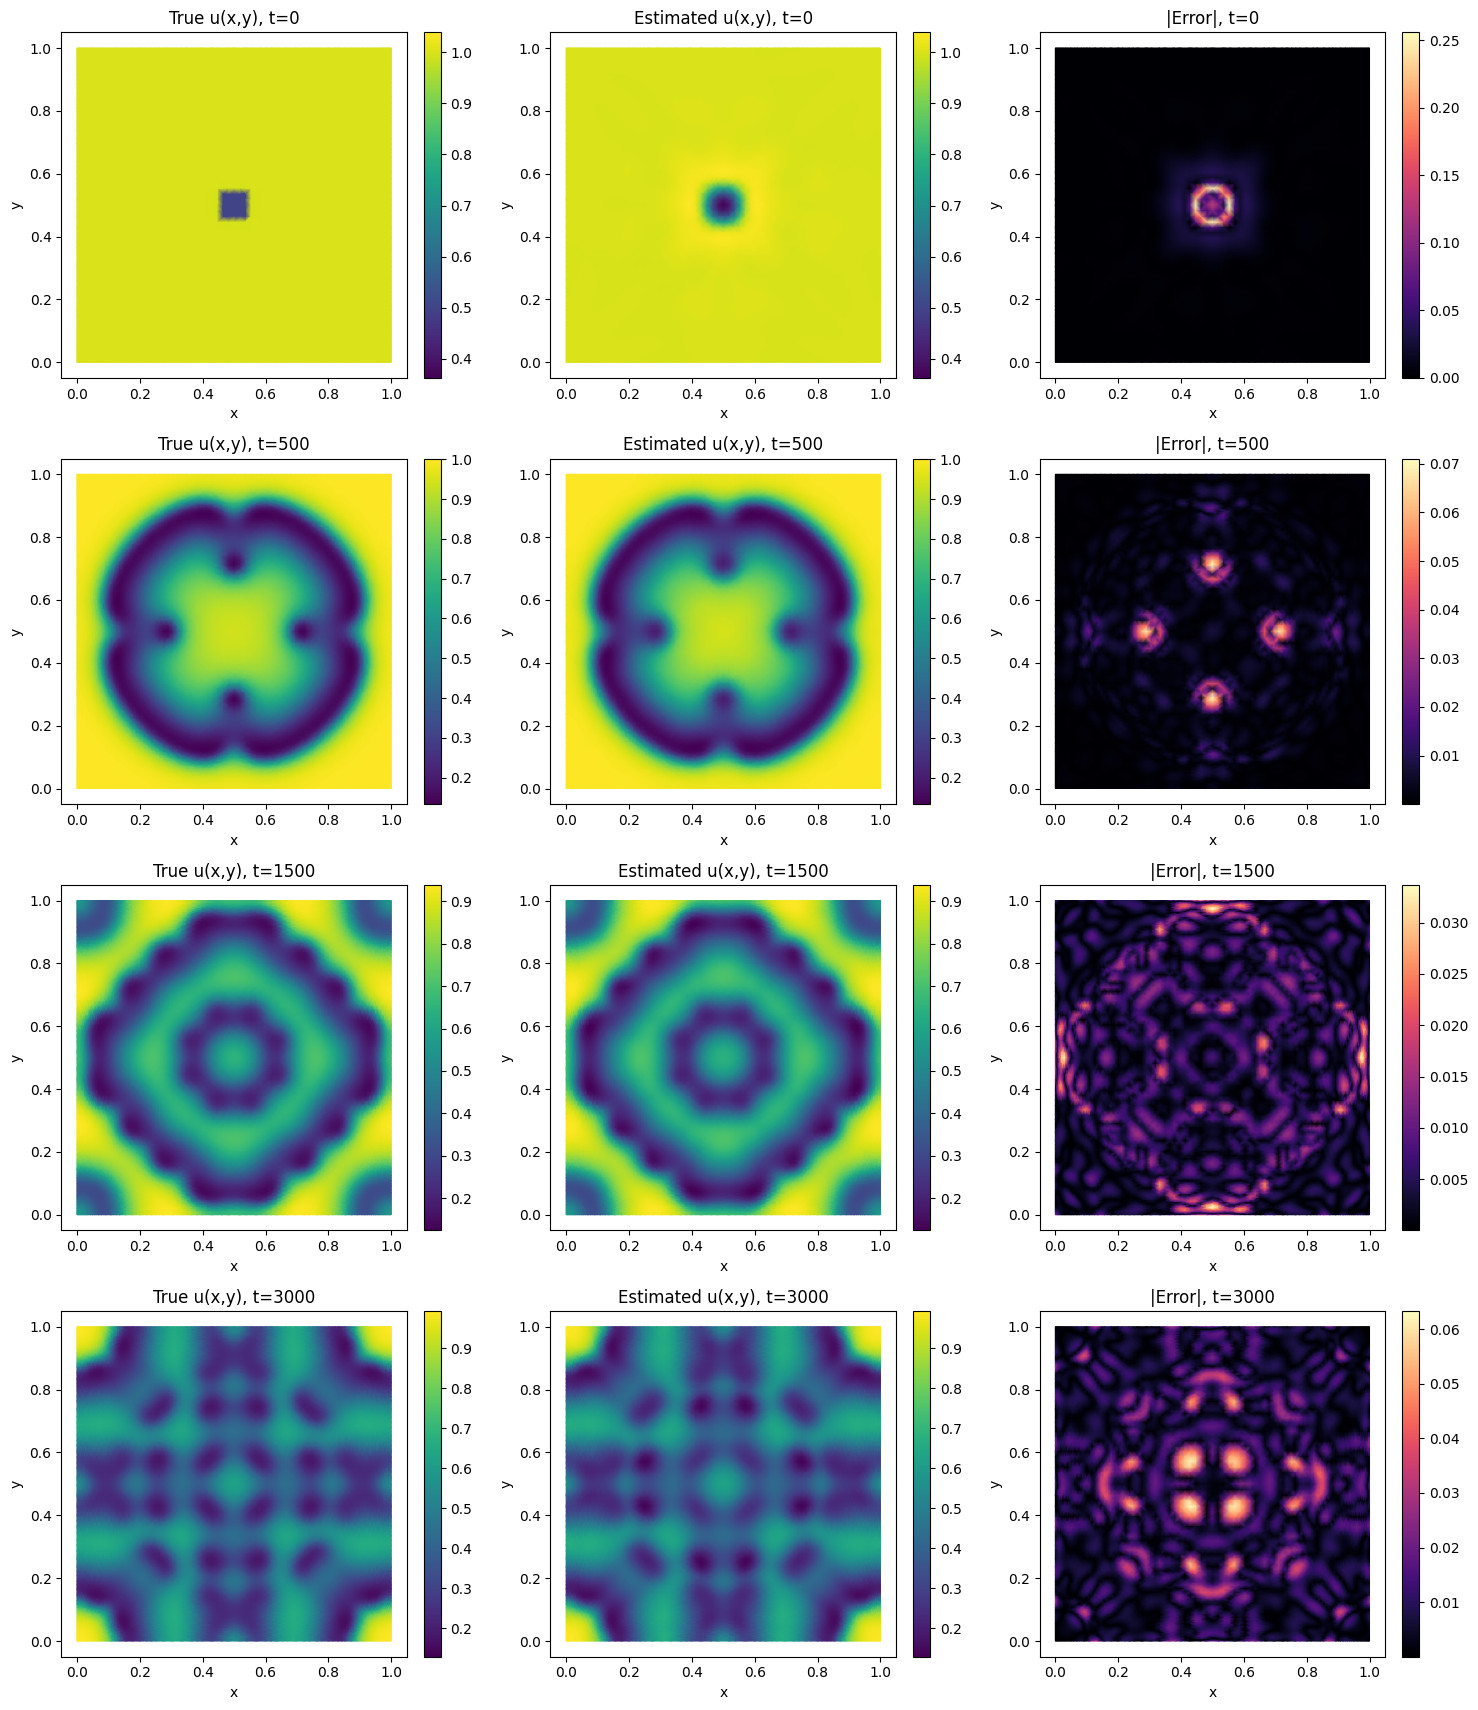

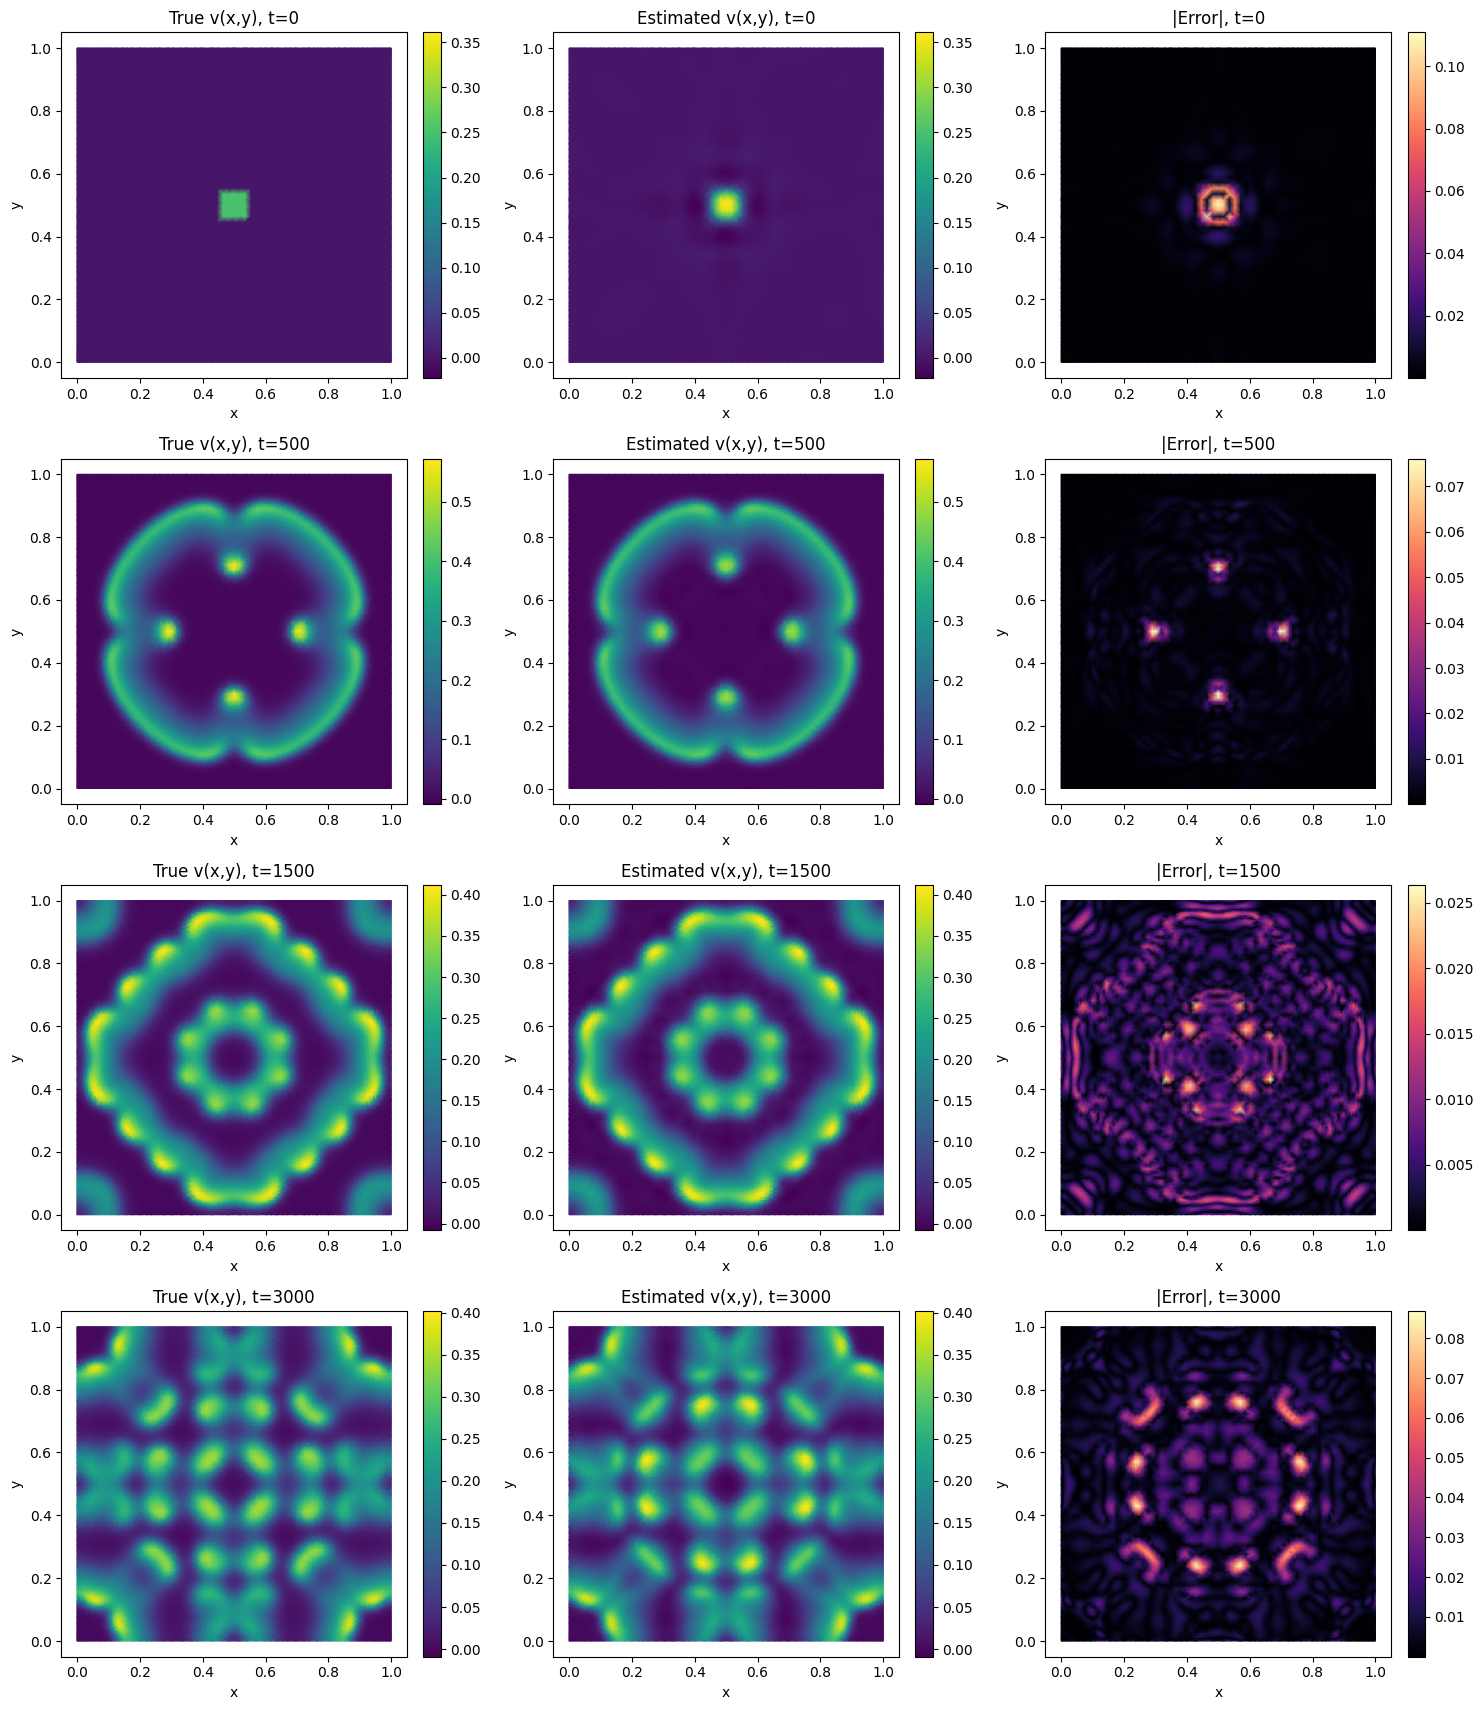

In [48]:
# Specify snapshot times
plot_times = [0,500,1500,3000]

evaluate_pretrained(plot_times,u_nn,v_nn)


# Running models with stage A or B training

In [15]:
def load_trained_model(model_name,path):

    stageA_path = f"{path}\{model_name}"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    ckpt = torch.load(stageA_path, map_location=device)

    # Check that the normalization bounds match
    current = dict(x_min=float(x_min), x_max=float(x_max),
                y_min=float(y_min), y_max=float(y_max),
                t_min=float(t_min), t_max=float(t_max))
    assert all(abs(ckpt["bounds"][k_] - current[k_]) < 1e-9 for k_ in current), \
        f"Bounds mismatch! saved={ckpt['bounds']} current={current}"

    # Build the networks (same architecture as when saved)
    u_nn  = u_net().to(device)          # or ScaledMLP().to(device) if you use that class
    v_nn  = v_net().to(device)          # or ScaledMLP().to(device)
    Du_nn = Du_net().to(device)
    Dv_nn = Dv_net().to(device)

    u_nn.load_state_dict(ckpt["u_nn"])
    v_nn.load_state_dict(ckpt["v_nn"])
    Du_nn.load_state_dict(ckpt["Du_nn"])
    Dv_nn.load_state_dict(ckpt["Dv_nn"])

    # Re-create the D function wrappers around the loaded networks
    Du_fn, Dv_fn = make_D_fns(Du_nn, Dv_nn)

    # Restore the loss settings used in Stage A
    # dt_be, t_lo_be = ckpt["dt_be"], ckpt["t_lo_be"]
    # sigma_u, sigma_v = ckpt["sigma_u"], ckpt["sigma_v"]

    # Freeze u, v (as in Stage A) and switch to eval mode for inference
    for p in list(u_nn.parameters()) + list(v_nn.parameters()):
        p.requires_grad_(False)
    for m in (u_nn, v_nn, Du_nn, Dv_nn):
        m.eval()

    print("Loaded Stage B checkpoint. Last step:", ckpt["step"])
    return u_nn, v_nn, Du_nn, Dv_nn

## Specify Name of The model below

In [41]:
model_name = "uv_10000_pts_stage_b.pt"
path = fr"C:\Users\Karan\Desktop\PINNS_literature_review\gray_scott_model\models\cons_pinn\checkpoints_{param}\trained_stage_b"

u_nn_trained, v_nn_trained, Du_nn, Dv_nn =  load_trained_model(model_name, path)

Loaded Stage B checkpoint. Last step: 150


In [18]:
def evaluate_trained(plot_times,u_nn,v_nn,Du_nn,Dv_nn):

    # ---------------------------------------------------------
    # Settings
    # ---------------------------------------------------------
    # plot_times = [0, 500, 1500, 3000]   # multiples of 10 in [0, 3000]

    # True diffusion coefficients
    D_true_fn = lambda x, y: 2e-5 * (1 + np.sin(np.pi * x) * np.sin(np.pi * y))
    Dv_true = 1e-5

    # ---------------------------------------------------------
    # Mesh from the data
    # ---------------------------------------------------------
    x_all = df["x"].values
    y_all = df["y"].values
    triang = mtri.Triangulation(x_all, y_all)

    x_t = torch.tensor(x_all, dtype=torch.float32, device=device).reshape(-1, 1)
    y_t = torch.tensor(y_all, dtype=torch.float32, device=device).reshape(-1, 1)

    # ---------------------------------------------------------
    # Predictions
    # ---------------------------------------------------------
    @torch.no_grad()
    def predict_uv(t_val):
        t_t = torch.full_like(x_t, float(t_val))
        X = torch.cat([
            normalize(x_t, x_min, x_max),
            normalize(y_t, y_min, y_max),
            normalize(t_t, t_min, t_max)
        ], dim=1)
        return u_nn(X).cpu().numpy().ravel(), v_nn(X).cpu().numpy().ravel()

    @torch.no_grad()
    def predict_D():
        X = torch.cat([
            normalize(x_t, x_min, x_max),
            normalize(y_t, y_min, y_max)
        ], dim=1)
        return Du_nn(X).cpu().numpy().ravel()

    # ---------------------------------------------------------
    # Heatmap helper
    # ---------------------------------------------------------
    def heat(ax, values, title, vmin=None, vmax=None, cmap="viridis"):
        cf = ax.tripcolor(triang, values, shading="gouraud", cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")
        plt.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)

    # ---------------------------------------------------------
    # u and v: true | estimated | |error|, one row per time
    # ---------------------------------------------------------
    preds = {t: predict_uv(t) for t in plot_times}

    for field, idx in [("u", 0), ("v", 1)]:
        n = len(plot_times)
        fig, axes = plt.subplots(n, 3, figsize=(15, 4.3 * n), squeeze=False)

        for i, t in enumerate(plot_times):
            true = df[f"{field}_{t}"].values
            pred = preds[t][idx]
            err = np.abs(pred - true)

            vmin = min(true.min(), pred.min())
            vmax = max(true.max(), pred.max())

            heat(axes[i, 0], true, f"True {field}(x,y), t={t}", vmin, vmax)
            heat(axes[i, 1], pred, f"Estimated {field}(x,y), t={t}", vmin, vmax)
            heat(axes[i, 2], err,  f"|Error|, t={t}", cmap="magma")

        plt.tight_layout()
        plt.show()

    # ---------------------------------------------------------
    # D(x,y): true | estimated | |error|
    # ---------------------------------------------------------
    D_est = predict_D()
    D_true = D_true_fn(x_all, y_all)

    share_scale = False   # set True once the estimate is in the right range

    u0 = 1e-5   # plot in units of 1e-5
    if share_scale:
        vmin = min(D_true.min(), D_est.min()) / u0
        vmax = max(D_true.max(), D_est.max()) / u0
        lim_true = lim_est = (vmin, vmax)
    else:
        lim_true = (D_true.min() / u0, D_true.max() / u0)
        lim_est  = (None, None)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    heat(axes[0], D_true / u0, "True D(x,y) [x1e-5]", *lim_true)
    heat(axes[1], D_est / u0,  "Estimated D(x,y) [x1e-5]", *lim_est)
    heat(axes[2], np.abs(D_est - D_true) / u0, "|Error| [x1e-5]", cmap="magma")
    plt.tight_layout()
    plt.show()

## Run the following cells to evaluate trained model

Numerical Metrics

In [19]:
def metrics_D(Du_nn, Dv_nn):

    # Evaluate on all mesh points
    x_all = torch.tensor(df["x"].values, dtype=torch.float32, device=device).reshape(-1, 1)
    y_all = torch.tensor(df["y"].values, dtype=torch.float32, device=device).reshape(-1, 1)

    with torch.no_grad():
        Du_pred = Du_nn(torch.cat([normalize(x_all, x_min, x_max),
                                normalize(y_all, y_min, y_max)], dim=1)).cpu().numpy().ravel()

    x_np, y_np = df["x"].values, df["y"].values
    Du_true = 2e-5 * (1 + np.sin(np.pi * x_np) * np.sin(np.pi * y_np))

    # 1. MSE (absolute units)
    mse = np.mean((Du_pred - Du_true) ** 2)
    rmse = np.sqrt(mse)

    # 2. Relative L2 error (RMSE as a fraction of the true D's RMS)
    rel_l2 = np.sqrt(np.sum((Du_pred - Du_true) ** 2) / np.sum(Du_true ** 2))

    # 3. The paper's error (Eq. 7): normalized by the variation of D_true around its mean,
    #    so it is not flattered by a large constant offset in D
    L_paper = np.sqrt(np.mean((Du_true - Du_pred) ** 2) / np.mean((Du_true - Du_true.mean()) ** 2))

    print("\nDiffusion coefficient Du(x,y) metrics:")
    print(f"MSE            : {mse:.3e}")
    print(f"RMSE           : {rmse:.3e}  ({rmse/1e-5:.3f} x1e-5)")
    print(f"Relative L2    : {rel_l2*100:.2f}%")
    print(f"Paper error L  : {L_paper*100:.2f}%")
    print(f"Mean Du pred / true: {Du_pred.mean():.3e} / {Du_true.mean():.3e}")

    print("\nDiffusion coefficient Dv metrics:")
    Dv_est, Dv_true = Dv_nn.value().item(), 1e-5
    print(f"Dv: {Dv_est:.3e} vs {Dv_true:.3e} | relative error {abs(Dv_est-Dv_true)/Dv_true*100:.2f}%")

In [42]:
metrics(u_nn_trained, v_nn_trained)                      # all mesh points
metrics_D(Du_nn, Dv_nn)

Evaluating on all 10201 mesh points

for u -->
MSE               : 5.730e-05
RMSE              : 7.570e-03
Relative L2       : 1.08%
Paper error L     : 2.69%
Mean pred / true  : 6.400e-01 / 6.390e-01

for v -->
MSE               : 4.132e-05
RMSE              : 6.428e-03
Relative L2       : 4.75%
Paper error L     : 6.08%
Mean pred / true  : 8.447e-02 / 8.427e-02

Diffusion coefficient Du(x,y) metrics:
MSE            : 9.465e-13
RMSE           : 9.729e-07  (0.097 x1e-5)
Relative L2    : 3.90%
Paper error L  : 19.11%
Mean Du pred / true: 2.366e-05 / 2.440e-05

Diffusion coefficient Dv metrics:
Dv: 1.043e-05 vs 1.000e-05 | relative error 4.35%


Visualization

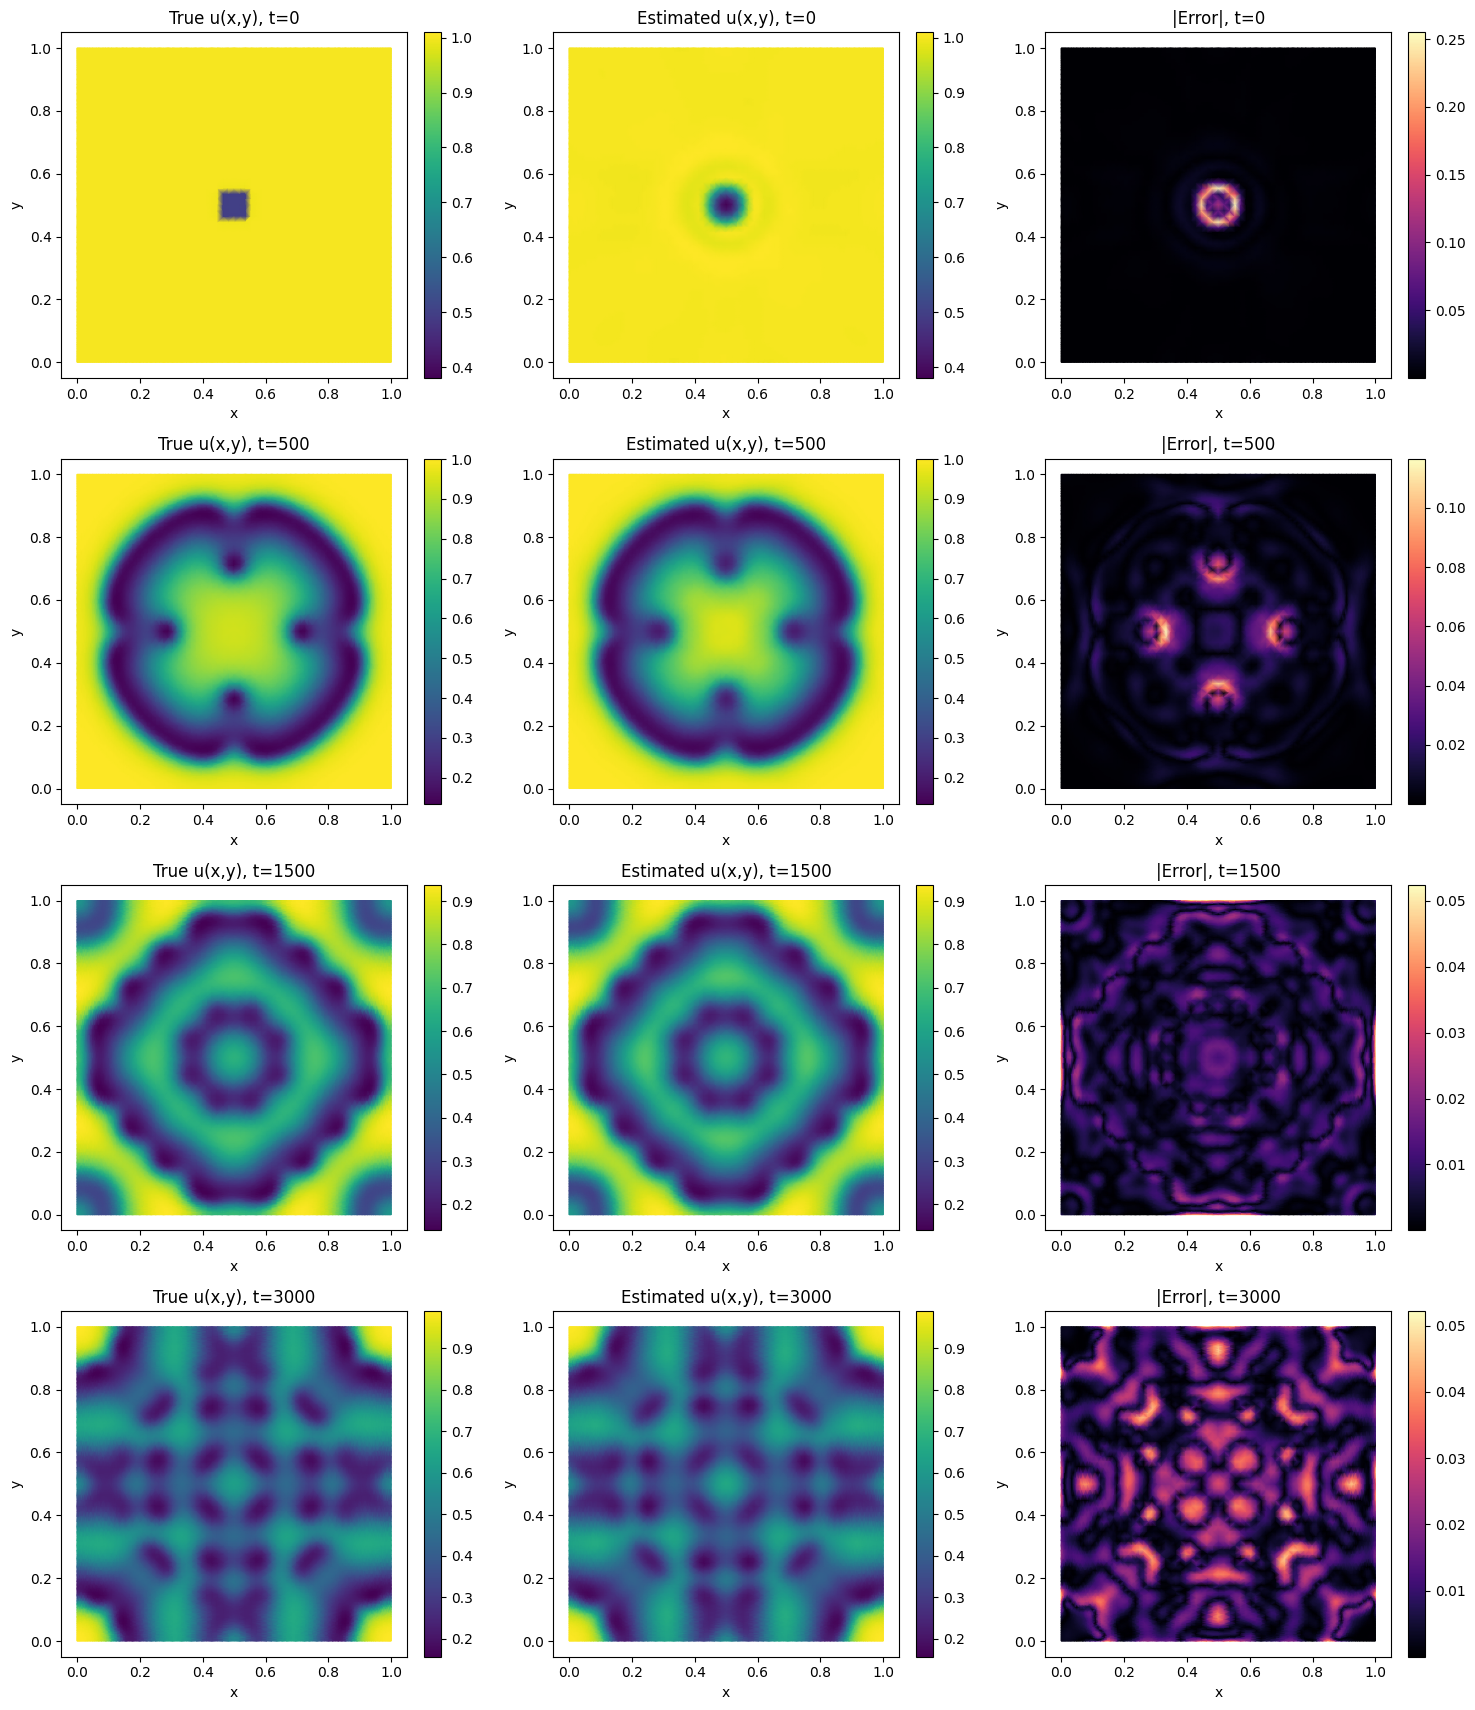

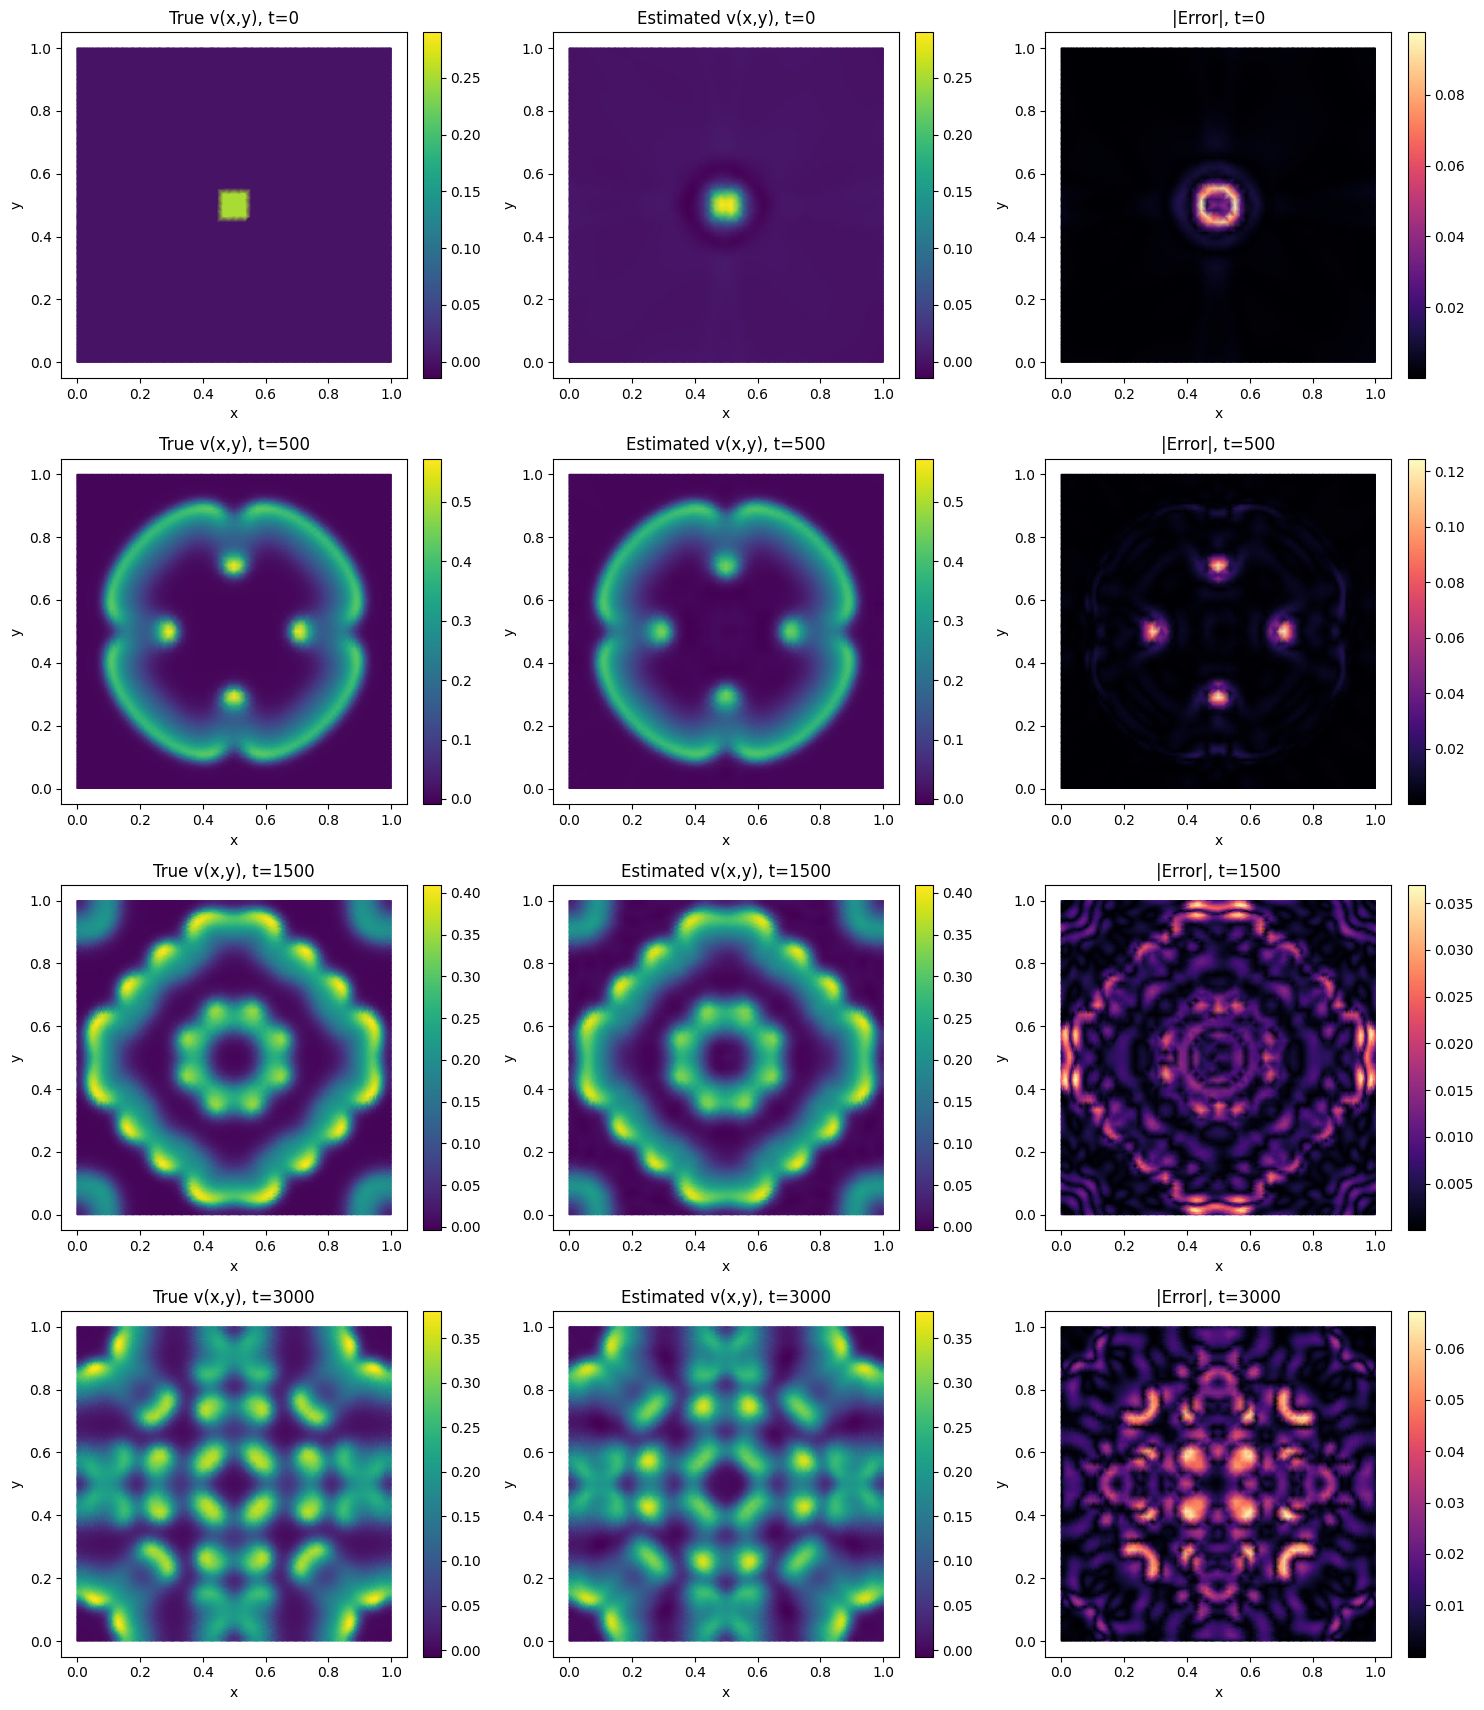

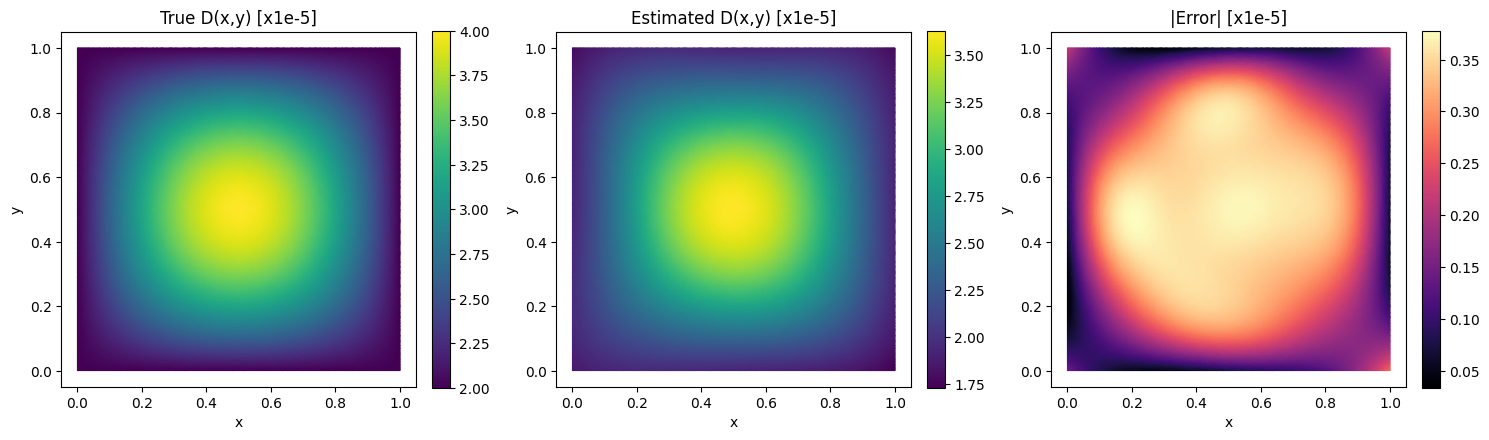

In [40]:
plot_times = [0,500,1500,3000]

evaluate_trained(plot_times,u_nn_trained,v_nn_trained,Du_nn,Dv_nn)